# 02 · Analisis & Visualisasi

Membaca data yang sudah tersimpan (tanpa scraping ulang), melakukan eksplorasi singkat, lalu membuat **match report**.

In [1]:
import sys, json
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from src.visualize import report_dari_raw, shotmap_per_tim_dari_raw

pd.set_option("display.max_columns", None)

## Pilih pertandingan
Nama folder sama dengan yang ada di `data/raw/` dan `data/processed/`.

In [2]:
print([p.name for p in Path("../data/processed").iterdir() if p.is_dir()])

['spain-vs-croatia_15534081']


In [3]:
MATCH = "spain-vs-croatia_15534081"  # ganti sesuai nama folder

PROC = Path("../data/processed") / MATCH
RAW = Path("../data/raw") / MATCH

info = json.loads((PROC / "match_info.json").read_text())
shots = pd.read_csv(PROC / "shots.csv")
stats = pd.read_csv(PROC / "stats.csv") if (PROC / "stats.csv").exists() else pd.DataFrame()
info

{'event_id': 15534081,
 'home': 'Spain',
 'away': 'Croatia',
 'home_score': 4,
 'away_score': 1,
 'tournament': 'UEFA Nations League, League A, Gr. 3',
 'date': '2026-09-29'}

## Eksplorasi tembakan

In [4]:
shots.head()

,time,addedTime,player.name,player.shortName,player.position,isHome,team,shotType,situation,bodyPart,goalMouthLocation,xg,xgot,playerCoordinates.x,playerCoordinates.y
0,2,NaN,Lamine Yamal,L. Yamal,M,True,Spain,goal,assisted,left-foot,low-left,0.147937,0.842909,14.5,62.7
1,4,NaN,Marc Cucurella,M. Cucurella,D,True,Spain,block,regular,left-foot,low-left,0.055460,0.000000,6.8,30.6
2,4,NaN,Alex Baena,A. Baena,M,True,Spain,save,assisted,right-foot,low-left,0.261486,0.726096,13.2,54.5
3,20,NaN,Martín Zubimendi,M. Zubimendi,M,True,Spain,block,assisted,left-foot,low-centre,0.063653,0.000000,19.5,48.8
4,20,NaN,Pau Cubarsí,P. Cubarsí,D,True,Spain,miss,regular,right-foot,close-left,0.017041,0.000000,24.7,67.7


In [5]:
# Ringkasan per tim
shots.groupby("team").agg(
    tembakan=("xg", "size"),
    gol=("shotType", lambda s: (s == "goal").sum()),
    total_xg=("xg", "sum"),
).round(2)

,tembakan,gol,total_xg
team,,,
Croatia,5,1,0.47
Spain,16,4,1.82


In [6]:
# Pemain dengan total xG tertinggi
(shots.groupby(["team", "player.name"])["xg"].agg(["count", "sum"])
      .rename(columns={"count": "tembakan", "sum": "total_xg"})
      .sort_values("total_xg", ascending=False).round(2).head(10))

tembakan  total_xg
team    player.name                         
Spain   Marc Pubill              1      0.41
        Fermín López             4      0.37
Croatia Dion Drena Beljo         2      0.31
Spain   Alex Baena               1      0.26
        Lamine Yamal             2      0.26
        Víctor Muñoz             1      0.21
        Nico Williams            2      0.14
Croatia Luka Modrić              1      0.07
        Franjo Ivanović          1      0.07
Spain   Martín Zubimendi         1      0.06

In [7]:
# Tembakan berdasarkan situasi
pd.crosstab(shots["situation"], shots["team"])

team,Croatia,Spain
situation,,
assisted,4,12
corner,0,1
fast-break,1,0
regular,0,3


## Statistik pertandingan (passing)

In [8]:
if not stats.empty:
    display(stats[(stats["period"] == "ALL") & (stats["group"] == "Passes")])

,period,group,key,stat,Spain,Croatia,home_value,away_value
29,ALL,Passes,accuratePasses,Accurate passes,568,296,568.0,296.0
30,ALL,Passes,throwIns,Throw-ins,12,6,12.0,6.0
31,ALL,Passes,finalThirdEntries,Final third entries,58,34,58.0,34.0
32,ALL,Passes,finalThirdPhaseStatistic,Final third phase,153/184 (83%),57/72 (79%),153.0,57.0
33,ALL,Passes,accurateLongBalls,Long balls,17/27 (63%),20/38 (53%),17.0,20.0
34,ALL,Passes,accurateCross,Crosses,3/11 (27%),5/12 (42%),3.0,5.0


## Match report

Report tersimpan di: /Users/nurwaniqbal/Downloads/football-match-report/reports/figures/spain-vs-croatia_15534081.png


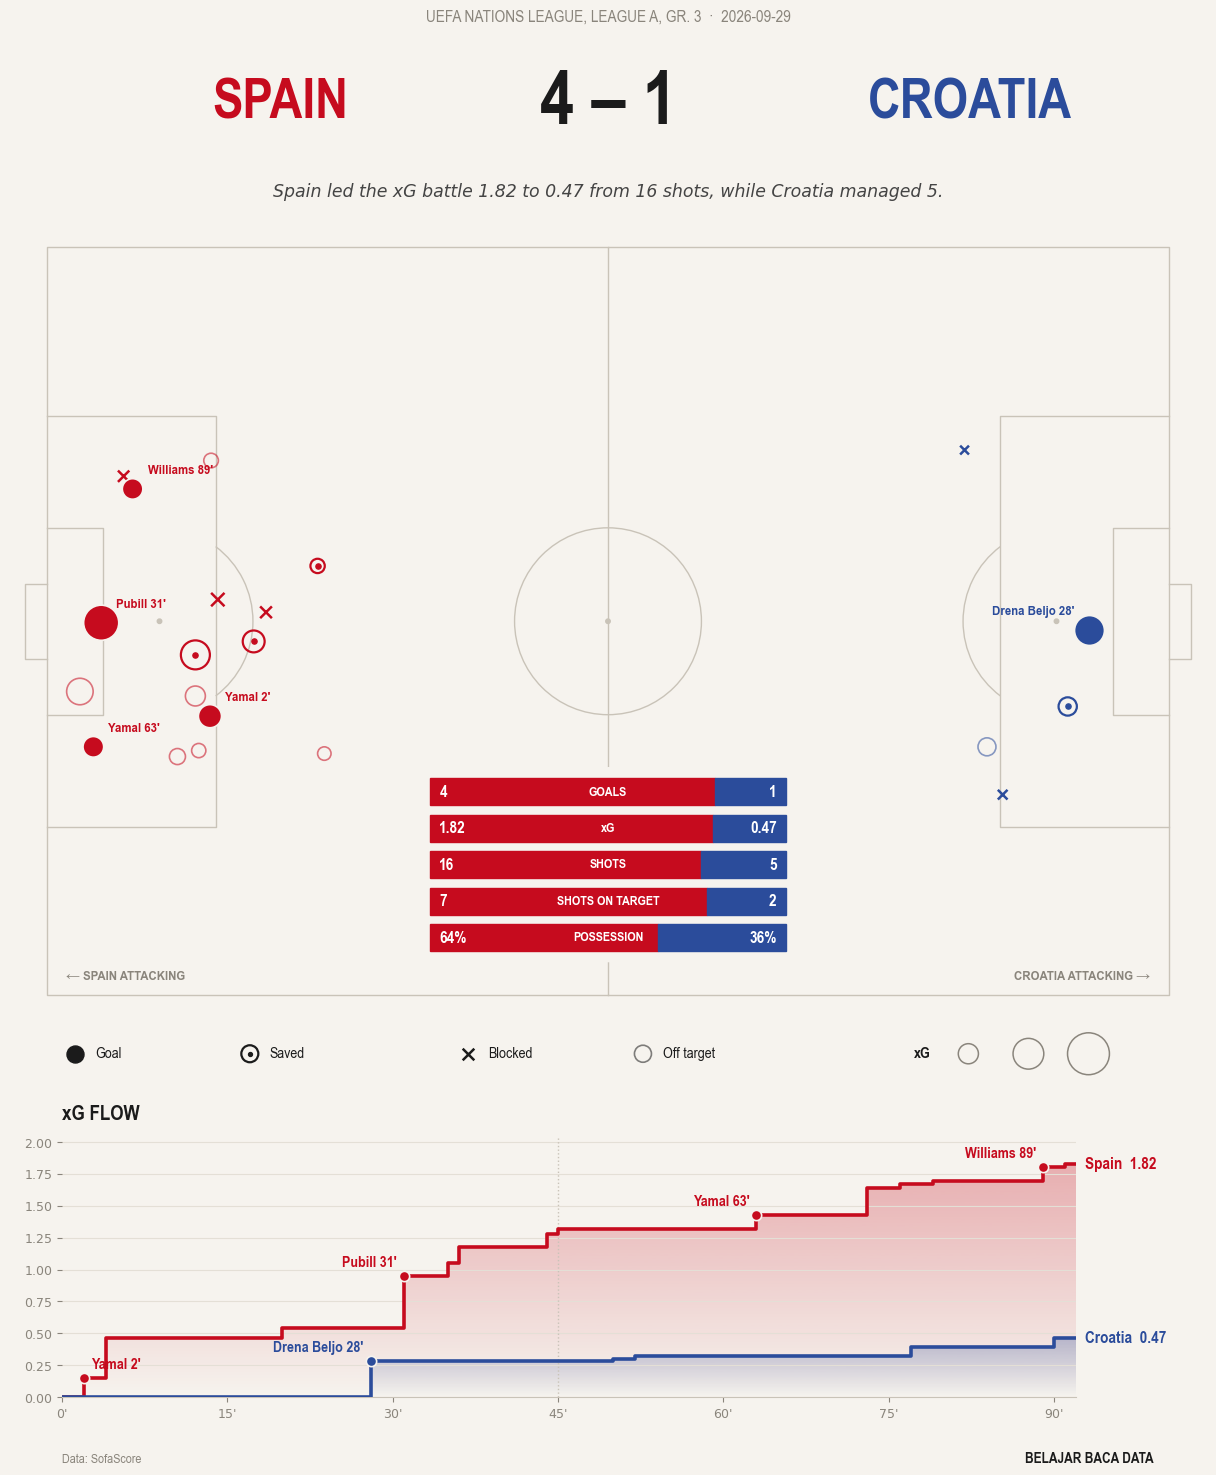

In [10]:
fig, axes = report_dari_raw(
    RAW,
    home_color="#c60b1e", away_color="#2b4c9b",
    bahasa="en",            # "id" = Indonesia, "en" = English
    pembuat="Belajar Baca Data",
    # insight="Tulis kesimpulan Anda sendiri di sini (opsional)",
)
plt.show()

## Shot map per tim

Shot map tersimpan di: /Users/nurwaniqbal/Downloads/football-match-report/reports/figures/spain-vs-croatia_15534081_shotmap.png


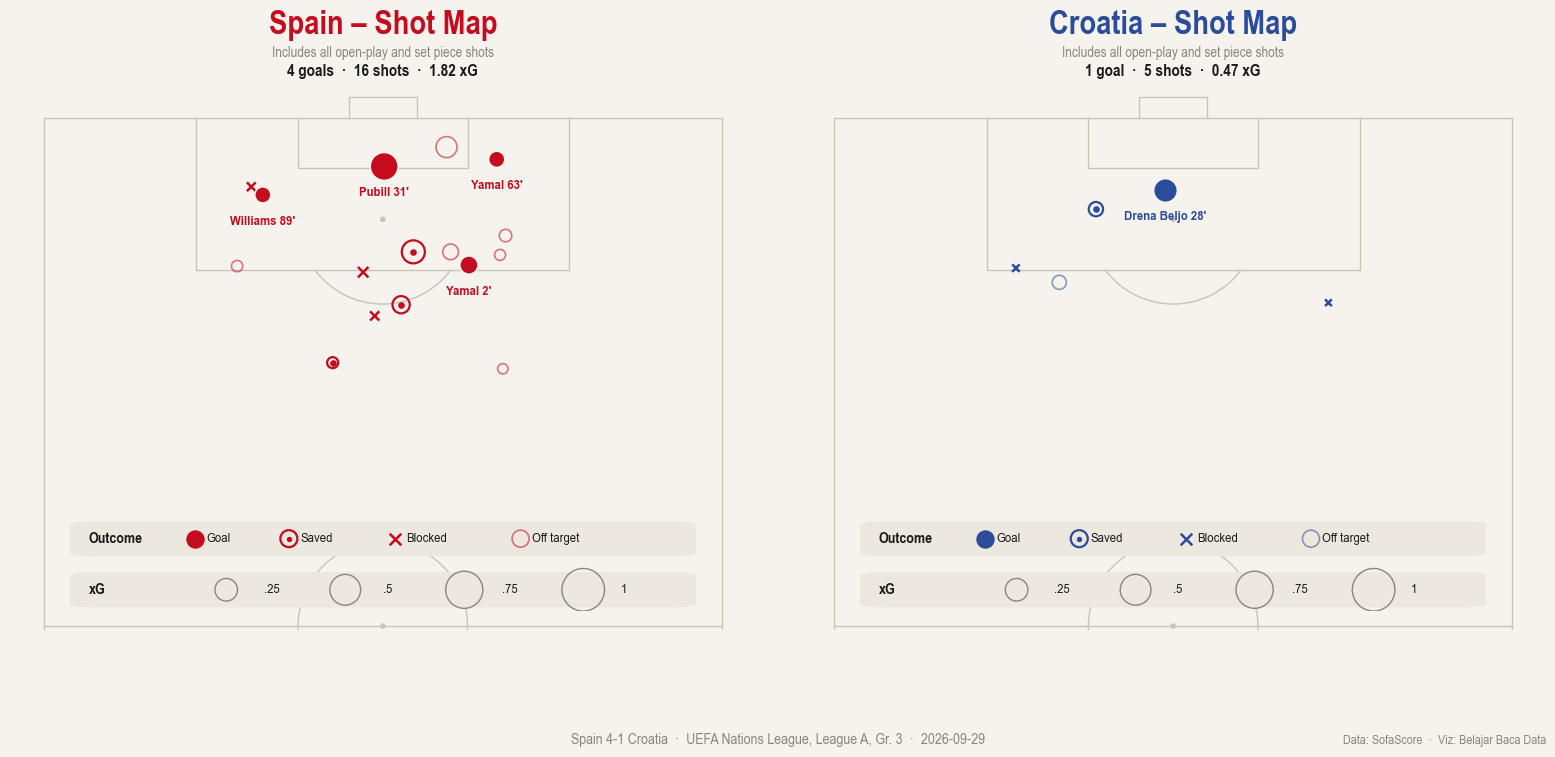

In [11]:
fig, axs = shotmap_per_tim_dari_raw(
    RAW,
    home_color="#c60b1e", away_color="#2b4c9b",
    bahasa="en",
    pembuat="Belajar Baca Data",
)
plt.show()